# Titanic Survival Prediction

## Machine Learning and Deep Learning Analysis

This notebook presents the analysis and model evaluation for the Titanic Survival Prediction project.

### Models Used

- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost
- Artificial Neural Network (ANN)
- 1D Convolutional Neural Network (1D CNN)

### Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("Titanic-Dataset (1).csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (891, 12)


,Name,Sex,Age,SibSp,Parch,Embarked,Ticket,Fare,Cabin,PassengerId,Pclass,Survived
0,"Braund, Mr. Owen Harris",male,22.0,1,0,S,A/5 21171,7.2500,NaN,1,3,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,C,PC 17599,71.2833,C85,2,1,1
2,"Heikkinen, Miss. Laina",female,26.0,0,0,S,STON/O2. 3101282,7.9250,NaN,3,3,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,S,113803,53.1000,C123,4,1,1
4,"Allen, Mr. William Henry",male,35.0,0,0,S,373450,8.0500,NaN,5,3,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         891 non-null    str    
 1   Sex          891 non-null    str    
 2   Age          714 non-null    float64
 3   SibSp        891 non-null    int64  
 4   Parch        891 non-null    int64  
 5   Embarked     889 non-null    str    
 6   Ticket       891 non-null    str    
 7   Fare         891 non-null    float64
 8   Cabin        204 non-null    str    
 9   PassengerId  891 non-null    int64  
 10  Pclass       891 non-null    int64  
 11  Survived     891 non-null    int64  
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [4]:
df.isnull().sum()

Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Embarked         2
Ticket           0
Fare             0
Cabin          687
PassengerId      0
Pclass           0
Survived         0
dtype: int64

In [5]:
df.describe()

,Age,SibSp,Parch,Fare,PassengerId,Pclass,Survived
count,714.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,29.699118,0.523008,0.381594,32.204208,446.000000,2.308642,0.383838
std,14.526497,1.102743,0.806057,49.693429,257.353842,0.836071,0.486592
min,0.420000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,20.125000,0.000000,0.000000,7.910400,223.500000,2.000000,0.000000
50%,28.000000,0.000000,0.000000,14.454200,446.000000,3.000000,0.000000
75%,38.000000,1.000000,0.000000,31.000000,668.500000,3.000000,1.000000
max,80.000000,8.000000,6.000000,512.329200,891.000000,3.000000,1.000000


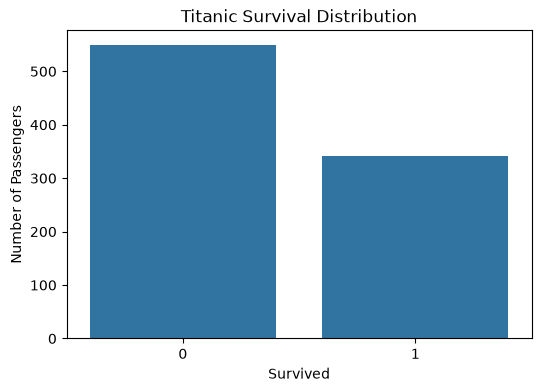

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Survived"
)

plt.title("Titanic Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")

plt.show()

In [7]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

X = df[features]

y = df["Survived"]

print("Selected Features:")
print(features)

Selected Features:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (712, 7)
Testing Data: (179, 7)


In [9]:
results = pd.read_csv(
    "results/model_results.csv"
)

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.810056,0.796610,0.681159,0.734375,0.828722
1,Logistic Regression,0.804469,0.793103,0.666667,0.724409,0.843742
2,XGBoost,0.804469,0.793103,0.666667,0.724409,0.818511
3,Gradient Boosting,0.798883,0.789474,0.652174,0.714286,0.817918
4,1D CNN,0.782123,0.741935,0.666667,0.702290,0.842556
5,ANN,0.776536,0.763636,0.608696,0.677419,0.850856
6,Decision Tree,0.765363,0.754717,0.579710,0.655738,0.797101


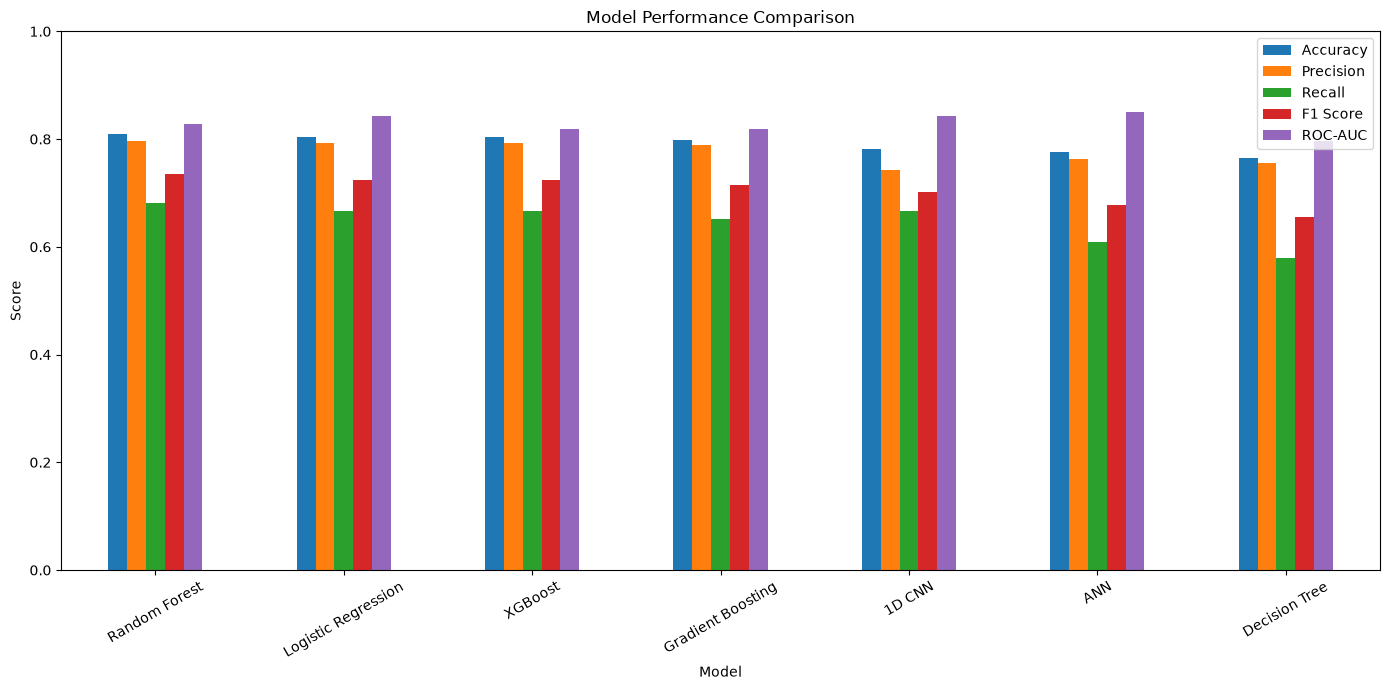

In [10]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [11]:
best_model = results.loc[
    results["F1 Score"].idxmax()
]

best_model

Model        Random Forest
Accuracy          0.810056
Precision          0.79661
Recall            0.681159
F1 Score          0.734375
ROC-AUC           0.828722
Name: 0, dtype: object

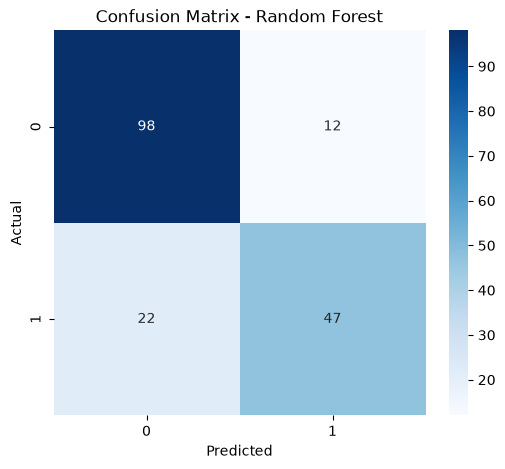

In [12]:
import joblib

model = joblib.load(
    "models/titanic_best_model.pkl"
)

y_pred = model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")

plt.show()

In [13]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.82      0.89      0.85       110
           1       0.80      0.68      0.73        69

    accuracy                           0.81       179
   macro avg       0.81      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179



In [14]:
rf_model = model.named_steps["model"]

preprocessor = model.named_steps["preprocessor"]

feature_names = (
    preprocessor
    .get_feature_names_out()
)

importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
4,num__Fare,0.257490
1,num__Age,0.243869
6,cat__Sex_male,0.153717
5,cat__Sex_female,0.136457
0,num__Pclass,0.087248
2,num__SibSp,0.046531
3,num__Parch,0.038527
9,cat__Embarked_S,0.016330
7,cat__Embarked_C,0.012098
8,cat__Embarked_Q,0.007733


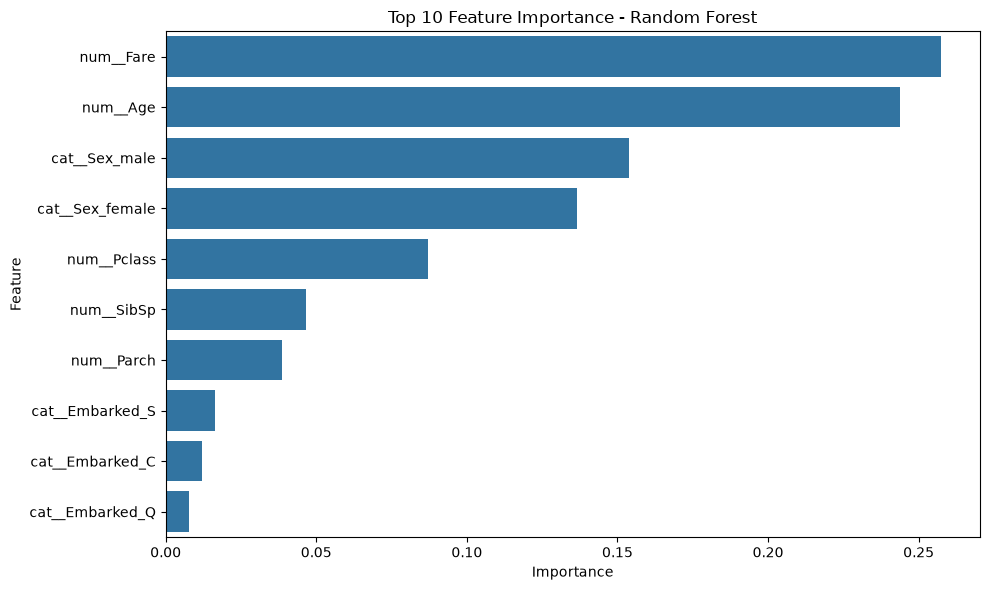

In [15]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importance - Random Forest")

plt.tight_layout()
plt.show()

## Conclusion

The Titanic Survival Prediction project compared five Machine Learning models and two Deep Learning models using Accuracy, Precision, Recall, F1 Score and ROC-AUC.

Based on the experimental results, Random Forest was selected as the best Machine Learning model according to F1 Score.

The trained Random Forest model was saved and integrated into a Streamlit application for interactive Titanic survival prediction.

The Streamlit application accepts passenger information and provides the predicted survival class together with survival and non-survival probabilities.